In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:

dfwh = pd.read_csv(r"C:\Users\DELL\Desktop\python imarticus\Shankhan@7\SOCR-HeightWeight.csv")
dfwh

,Index,Height(Inches),Weight(Pounds)
0,1,65.78331,112.9925
1,2,71.51521,136.4873
2,3,69.39874,153.0269
3,4,68.21660,142.3354
4,5,67.78781,144.2971
...,...,...,...
24995,24996,69.50215,118.0312
24996,24997,64.54826,120.1932
24997,24998,64.69855,118.2655
24998,24999,67.52918,132.2682


In [ ]:
dfwh.columns
dfwh.drop("Index",axis=1,inplace=True)
dfwh
dfwh.columns = ["Height","Weight"]
dfwh

,Height,Weight
0,65.78331,112.9925
1,71.51521,136.4873
2,69.39874,153.0269
3,68.21660,142.3354
4,67.78781,144.2971
...,...,...
24995,69.50215,118.0312
24996,64.54826,120.1932
24997,64.69855,118.2655
24998,67.52918,132.2682


## weight column eroor detection





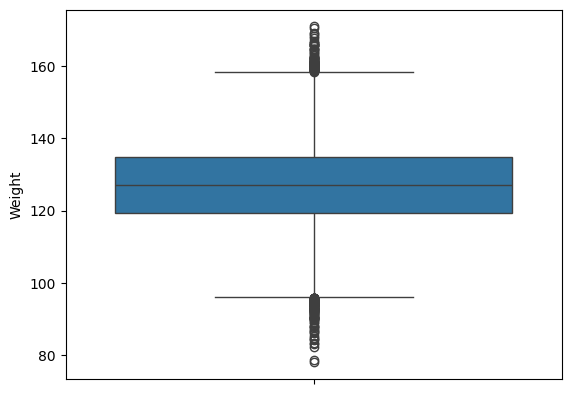

In [12]:
dfwh["Weight"].describe()
sns.boxplot(dfwh["Weight"])
plt.show()

In [ ]:
q1 = dfwh["Weight"].quantile(0.25)
q3 =  dfwh["Weight"].quantile(0.75)
iqr = q3-q1
lower = q1 - (1.5*iqr)
upper = q3+(1.5*iqr)

dfwh[(dfwh["Weight"]<lower) | (dfwh["Weight"]>upper)]


,Height,Weight
156,70.98112,158.95620
249,65.93895,84.35980
293,69.13438,92.74955
367,72.32489,168.22900
446,69.16807,162.41090
...,...,...
24187,69.21155,161.85040
24610,66.56804,82.38298
24750,70.82192,159.63440
24835,65.17339,94.40946


## data trimming

In [29]:
df1 = dfwh.copy()
ind = dfwh[(dfwh["Weight"]<lower) | (dfwh["Weight"]>upper)].index
dfwh.drop(ind,inplace=True)
dfwh

,Height,Weight
0,65.78331,112.9925
1,71.51521,136.4873
2,69.39874,153.0269
3,68.21660,142.3354
4,67.78781,144.2971
...,...,...
24995,69.50215,118.0312
24996,64.54826,120.1932
24997,64.69855,118.2655
24998,67.52918,132.2682


## capping

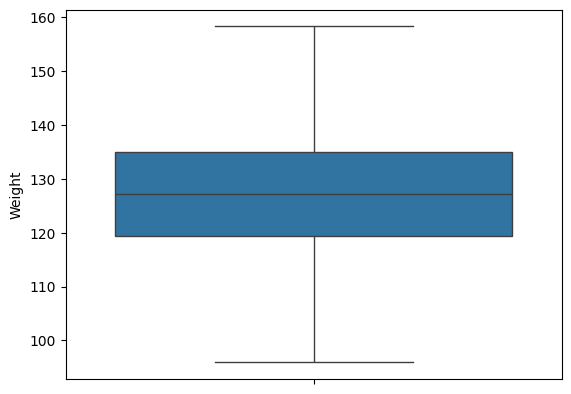

In [34]:
df1["Weight"]=df1["Weight"].map(lambda x:  lower if x<lower else upper if x>upper else x )
df1["Weight"]
sns.boxplot(df1["Weight"])
plt.show()